# 02 · Stimulate and observe

**Separate a supplied input from the activity the model produces.**

We apply two direct numerical pulses to the same **14-neuron, 22-edge fixture** inspected in notebook 01, then follow the entry cells, descending readouts, and motor readouts. These are synthetic teaching inputs and dimensionless simulated activities. They are not measured firing rates, natural sensory transduction, or the current Minecraft controller.

This notebook is independent: it loads and verifies its own data. Setup: [research quickstart](../docs/RESEARCH_QUICKSTART.md). Model assumptions and the live system: [current model card](../docs/MODEL_CARD.md).

In [1]:
import os
import sys
from pathlib import Path

# Works when launched from the project root or this notebooks/ directory.
ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
        and (path / "research/example-v1/manifest.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the NeuroCraft Fly source directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATASET = ROOT / "research/example-v1"
FIGURES = Path(
    os.environ.get("NEUROCRAFT_RESEARCH_OUTPUT", str(ROOT / "artifacts/research-notebooks/figures"))
)

In [2]:
import math

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from scripts.research_example import ABS_TOL, REL_TOL, load_dataset, simulate, verify
from scripts.research_figures import export_figure, plot_stimulation


def show_table(headers, rows):
    def clean(value):
        return str(value).replace("|", " / ").replace("\n", " ")

    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(clean(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

## Verify the example, then run the engine again

Verification checks the packaged bytes, identities, and a fresh replay. We also compare every stored per-neuron activity value with a direct call to the existing Python `NeuralEngine` through `simulate()`, reporting the actual maximum difference and whether those values are exactly equal.

The notebooks use **numerical replay** with absolute tolerance `1e-12` and relative tolerance `1e-10` (`math.isclose` semantics), allowing small platform/libm differences only in declared floating-point values. Source IDs, configuration, code hashes, schemas, and the stored payload hashes remain exact. A failed check stops the notebook. After successful verification, `load_dataset(..., replay=False)` reads the verified tables without running the experiment a second time.

For the stricter same-platform check, run `uv run --locked python scripts/research_example.py verify`: the CLI defaults to **byte-exact replay**. Numerical replay and byte-exact replay are different checks; passing one is not a claim that the other passed.

In [3]:
report = verify(DATASET, tolerant=True)
example = load_dataset(DATASET, replay=False)
fresh = simulate()
stored_activity = {
    (row["condition"], int(row["step"]), int(row["body_id"])): float(row["activity"])
    for row in example["tables"]["activity"]
}
fresh_activity = {
    (row["condition"], row["step"], row["body_id"]): row["activity"]
    for row in fresh["tables"]["activity"]
}
assert stored_activity.keys() == fresh_activity.keys()
max_replay_difference = max(
    abs(value - fresh_activity[key]) for key, value in stored_activity.items()
)
assert all(
    math.isclose(value, fresh_activity[key], abs_tol=ABS_TOL, rel_tol=REL_TOL)
    for key, value in stored_activity.items()
)
print("Verification:", report["mode"])
print(
    f"Compared {len(stored_activity):,} per-neuron samples; "
    f"maximum difference = {max_replay_difference:g}."
)
print("Per-neuron values exactly equal:", max_replay_difference == 0.0)
print(f"Replay tolerances: absolute={ABS_TOL:g}, relative={REL_TOL:g}; identities remain exact.")

Verification: numerical_replay
Compared 4,242 per-neuron samples; maximum difference = 0.
Per-neuron values exactly equal: True
Replay tolerances: absolute=1e-12, relative=1e-10; identities remain exact.


## Declare the experiment

All three conditions start with zero activity and zero delayed history. The reference engine uses 10 ms steps, a 50 ms leak time, recurrent gain 0.9, a `tanh` nonlinearity, and no noise. No parameters are learned.

The left direct drive is +0.8 on body **805722** during intervals starting at 100–290 ms, ending at 300 ms. The right drive is +0.8 on body **77185** during intervals starting at 500–690 ms, ending at 700 ms. Other cells have no direct drive.

An input row at time `n × 10 ms` is applied while computing the next state. Activity rows include the committed reset at 0 ms and states through 1,000 ms. With the declared delay convention, an edge of delay `d` reads state `a[n-d]` when computing `a[n+1]`. Do not interpret the graph's edge count as a measured biological latency.

In [4]:
show_table(
    ["Inspection pool", "Source body ID(s)", "Aggregation"],
    [
        [name, ", ".join(str(body) for body in members), "Signed mean; one neuron here"]
        for name, members in example["manifest"]["readout_policy"]["pools"].items()
    ],
)
print("These pools inspect model activity; they issue no Minecraft action.")

| Inspection pool | Source body ID(s) | Aggregation |
| --- | --- | --- |
| DNg07_L | 27143 | Signed mean; one neuron here |
| DNg07_R | 28949 | Signed mean; one neuron here |
| hg1_motor_L | 800241 | Signed mean; one neuron here |
| hg1_motor_R | 800917 | Signed mean; one neuron here |
| sensory_L | 805722 | Signed mean; one neuron here |
| sensory_R | 77185 | Signed mean; one neuron here |

These pools inspect model activity; they issue no Minecraft action.


## Follow the response

The first panel shows what we supplied. The next three show what the model produced. Each readout is an unscaled signed mean; in this example every pool has one member. Negative activity is permitted by this rate model. Curves show every recorded sample without smoothing.

The two input cells have different source identities and retained pathways. A left/right difference in this selected fixture is not a measurement of a whole fly's behavioral asymmetry.

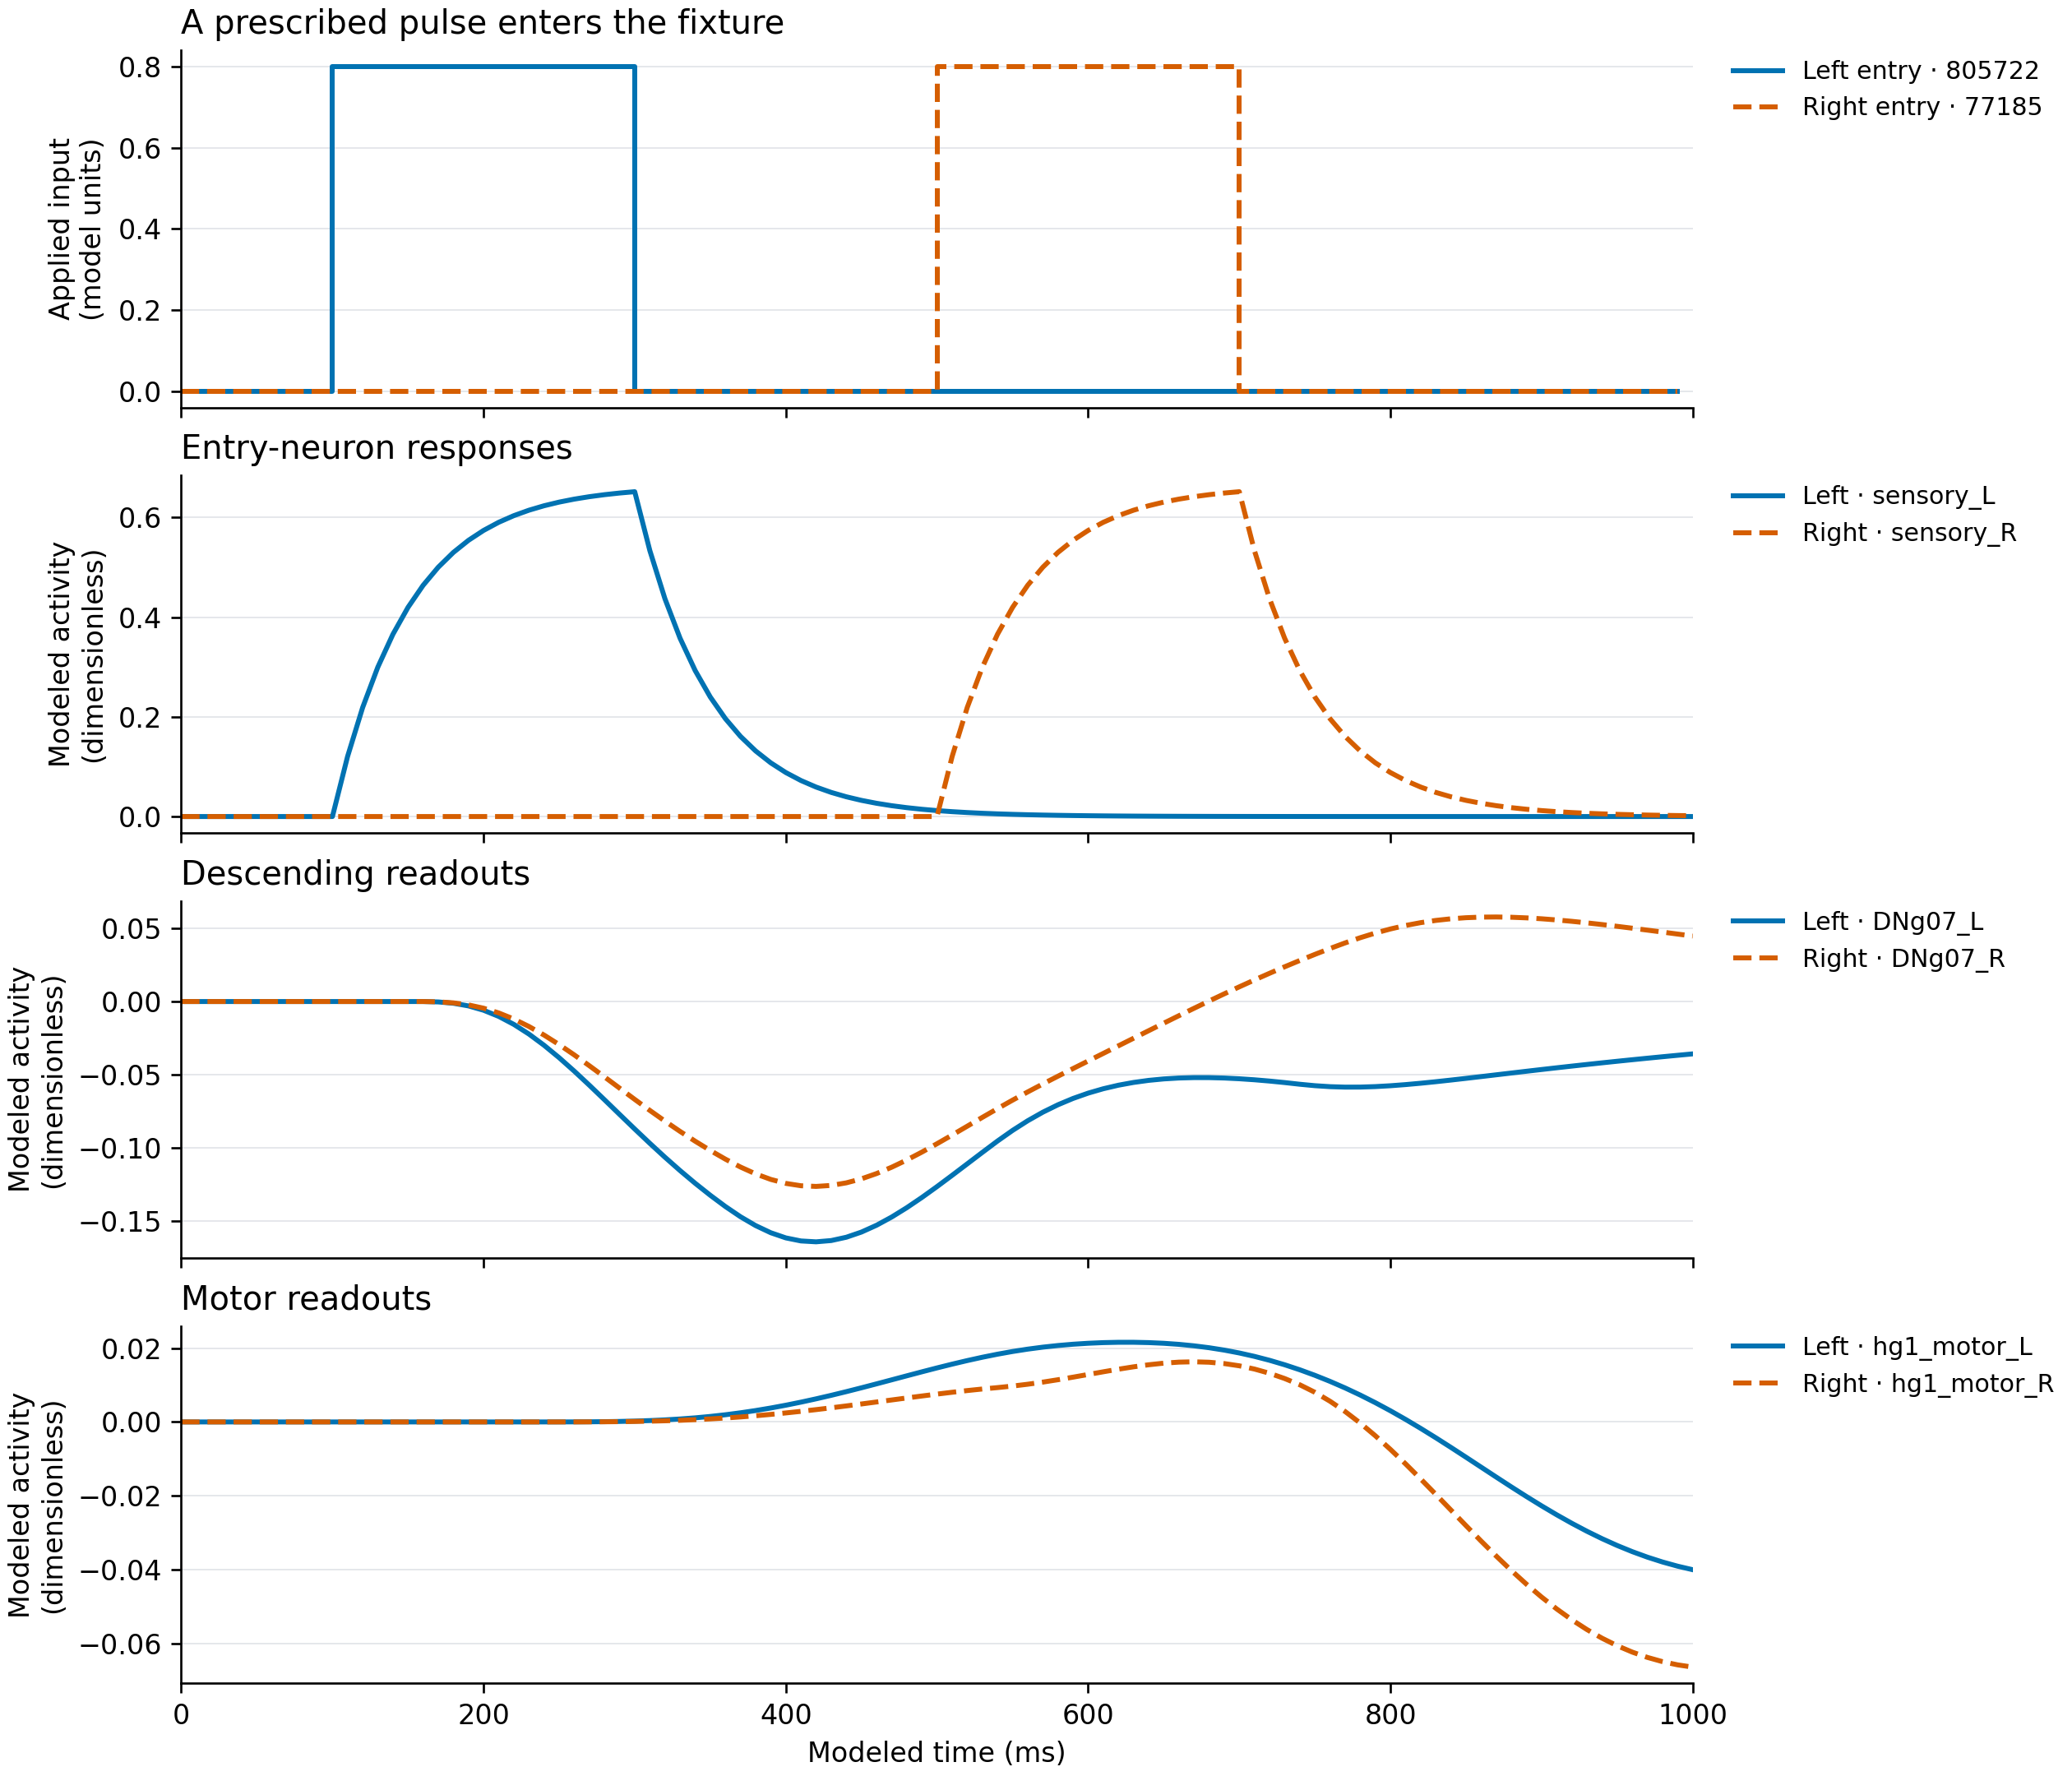

Saved 02_stimulus_and_response.svg and .png to the configured figure directory.


In [5]:
figure = plot_stimulation(example["tables"]["inputs"], example["tables"]["readouts"])
_, png_path = export_figure(figure, FIGURES / "02_stimulus_and_response")
display(Image(filename=str(png_path)))
plt.close(figure)
print("Saved 02_stimulus_and_response.svg and .png to the configured figure directory.")

## Quantify what the plot shows

The table reports the largest **absolute** activity and its first occurrence over the whole 1,000 ms run. The signed value at that peak preserves whether the excursion was positive or negative. These peak times are not estimates of response-onset latency. There is one deterministic run, so no error bars or biological sample size are implied.

In [6]:
original = example["summary"]["conditions"]["original"]
show_table(
    ["Pool", "Peak |activity|", "Signed value at peak", "First peak (modeled ms)"],
    [
        [
            pool,
            f"{metrics['peak_abs_activity']:.6f}",
            f"{metrics['signed_activity_at_peak']:.6f}",
            metrics["first_peak_step"] * 10,
        ]
        for pool, metrics in original.items()
    ],
)

| Pool | Peak |activity| | Signed value at peak | First peak (modeled ms) |
| --- | --- | --- | --- |
| DNg07_L | 0.163930 | -0.163930 | 420 |
| DNg07_R | 0.126128 | -0.126128 | 420 |
| hg1_motor_L | 0.040049 | -0.040049 | 1000 |
| hg1_motor_R | 0.066449 | -0.066449 | 1000 |
| sensory_L | 0.651875 | 0.651875 | 300 |
| sensory_R | 0.651875 | 0.651875 | 700 |

## Try a new pulse amplitude

Change `pulse_amplitude` and rerun this cell. This creates an **exploratory run in memory**, preserving the versioned dataset. The same engine and schedule run again; only the pulse amplitude changes. Since the model is recurrent and nonlinear, the output need not scale proportionally with the input.

Before running it, predict whether halving the input will halve both motor peaks. Then compare the actual values. This is a sensitivity exercise, not a fit to experimental physiology.

In [7]:
pulse_amplitude = 0.4  # Reference = 0.8; try another finite value.
exploratory = simulate(pulse_amplitude=pulse_amplitude)
show_table(
    ["Motor pool", "Reference peak |activity|", "Exploratory peak |activity|", "Pulse amplitude"],
    [
        [
            pool,
            f"{original[pool]['peak_abs_activity']:.6f}",
            f"{exploratory['summary']['conditions']['original'][pool]['peak_abs_activity']:.6f}",
            pulse_amplitude,
        ]
        for pool in ("hg1_motor_L", "hg1_motor_R")
    ],
)
assert example["manifest"]["input_schedule"]["pulses"][0]["amplitude"] == 0.8

| Motor pool | Reference peak |activity| | Exploratory peak |activity| | Pulse amplitude |
| --- | --- | --- | --- |
| hg1_motor_L | 0.040049 | 0.023220 | 0.4 |
| hg1_motor_R | 0.066449 | 0.038637 | 0.4 |

## The question a response cannot answer

A downstream response establishes that this model responds under these assumptions. It does not establish that the original assignment of connection weights is necessary, that this circuit is sufficient for a natural reflex, or that the live Minecraft system uses these inspection pools.

Continue to [03 · Change and compare](03_change_and_compare.ipynb) to test a matched weight shuffle and a no-input control. You can inspect the exact dynamics and stimulus code in [research_example.py](../scripts/research_example.py), and the versioned inputs and assumptions in the [dataset README](../research/example-v1/README.md).